In [123]:
import pandas as pd
import os
import  matplotlib.pyplot as plt

print(os.getcwd())
print(os.listdir())

#Previamente, cargamos en el directorio de este script, el archivo de venta de unidades de Febrero, el maestro de productos y el maestro de locales (todo anonimizado)

#Leemos el archivo de ventas de FEBRERO y lo guardamos en un Data Frame
df_ventas = pd.read_csv('Ventas_Febrero.csv', sep=';',thousands=".")

#Leemos el archivo de maestro de productos y de tiendas y los guardamos en un DF
df_productos = pd.read_excel('Maestro de Productos.xlsx')
df_tiendas = pd.read_excel('Maestro de Tiendas.xlsx')

#df_ventas.head()
#df_tiendas.head()
#df_productos.head()


/content
['.config', 'Maestro de Tiendas.xlsx', 'ventas_consolidadas.parquet', 'Ventas_Febrero.csv', 'Maestro de Productos.xlsx', 'sample_data']


In [124]:
print("")
df_ventas.info()
print("")
df_productos.info()
print("")
df_tiendas.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145521 entries, 0 to 145520
Data columns (total 3 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   ID_PRODUCTO  145520 non-null  object 
 1   ID_TIENDA    145518 non-null  float64
 2   Unidades     145519 non-null  float64
dtypes: float64(2), object(1)
memory usage: 3.3+ MB

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4411 entries, 0 to 4410
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Codigo Prod.             4405 non-null   float64
 1   Producto                 4410 non-null   object 
 2   productos.familia        4395 non-null   object 
 3   productos.unidadnegocio  4409 non-null   object 
 4   productos.famtablero     4368 non-null   object 
 5   productos.untablero      4404 non-null   object 
 6   P c IVA                  4411 non-null   float64
dtypes: float64(2), object(5)

A priori - el Maestro de tiendas es el unico que parece estar normalizado y limpio. El ID_TIENDA lo toma como un integer, tiene la misma cantidad de registros en todas las columnas

In [125]:
#Medimos el peso del archivo de ventas, para despues compararlo cuando lo comprimamos despues de normalizarlo
ruta_archivo = "Ventas_Febrero.csv"

peso_bytes_antes = os.path.getsize(ruta_archivo)

print(peso_bytes_antes)
print("Tamaño en MB:", round(peso_bytes_antes / (1024 ** 2), 4))

#Medimos el peso del archivo cuando lo cargamos en el data fram de python
memoria_bytes = df_ventas.memory_usage(deep=True).sum()

print("Memoria en bytes:", memoria_bytes)
print("Memoria en MB:", round(memoria_bytes / (1024 ** 2), 4))

2339680
Tamaño en MB: 2.2313
Memoria en bytes: 10273370
Memoria en MB: 9.7974


In [126]:
print("VENTAS")
print(df_ventas.shape)
print(df_ventas.dtypes)

print("\nPRODUCTOS")
print(df_productos.shape)
print(df_productos.dtypes)

print("\nTIENDAS")
print(df_tiendas.shape)
print(df_tiendas.dtypes)

VENTAS
(145521, 3)
ID_PRODUCTO     object
ID_TIENDA      float64
Unidades       float64
dtype: object

PRODUCTOS
(4411, 7)
Codigo Prod.               float64
Producto                    object
productos.familia           object
productos.unidadnegocio     object
productos.famtablero        object
productos.untablero         object
P c IVA                    float64
dtype: object

TIENDAS
(109, 4)
ID_TIENDA         int64
Nombre_Tienda    object
Region           object
Tipo_Tienda      object
dtype: object


Investigamos cuantas tiendas unicas hay y cuantos productos unicos hay --> utilizando el comando nunique

In [127]:
print(df_ventas.head(10))
print("\nValores únicos por columna:")
print(df_ventas.nunique())

  ID_PRODUCTO  ID_TIENDA  Unidades
0       10001     7672.0       2.0
1       10001     7966.0       1.0
2       10001     8059.0       5.0
3       10001     8145.0       6.0
4       10001     8409.0       1.0
5       10001     8419.0       1.0
6       10001     8420.0       9.0
7       10001     8618.0       3.0
8       10001     9618.0       2.0
9       10001    10636.0       0.0

Valores únicos por columna:
ID_PRODUCTO    2350
ID_TIENDA       109
Unidades       1947
dtype: int64


In [128]:
#Revision de si hay algun valor nulo / si hay cantidades con decimales
print("cantidad de valores nulos")
print(df_ventas.isnull().sum())

# el %1 calcula el resto de dividir todo por 1. si el resto es 0. .all() devuelve true si cumplen la condicion de enteros
#print("\n¿Todas las unidades son enteras?")
#print((df_ventas["Unidades"] % 1 == 0).all())

#print("\nValores mínimos y máximos:")
#print(df_ventas[["ID_TIENDA", "Unidades"]].agg(["min", "max"]))



cantidad de valores nulos
ID_PRODUCTO    1
ID_TIENDA      3
Unidades       2
dtype: int64


In [129]:
#Vamos a buscar las filas complicadas o sospechosas
print("Filas con valores nulos:")
display(df_ventas[df_ventas.isnull().any(axis=1)])


#Vamos a mirar el registro de la fila de unidades maximas
#df_ventas["Unidades"].idxmax()

#display(df_ventas.loc[df_ventas["Unidades"].idxmax()])


Filas con valores nulos:


,ID_PRODUCTO,ID_TIENDA,Unidades
145518,Total,NaN,8831728.0
145519,NaN,NaN,NaN
145520,Filtros aplicados: \nIncluido (1) 2026 (Año) +...,NaN,NaN


In [130]:
df_ventas_raw = df_ventas.copy()

df_ventas=df_ventas.dropna(subset=["ID_TIENDA"])

df_ventas_raw.info()
df_ventas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145521 entries, 0 to 145520
Data columns (total 3 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   ID_PRODUCTO  145520 non-null  object 
 1   ID_TIENDA    145518 non-null  float64
 2   Unidades     145519 non-null  float64
dtypes: float64(2), object(1)
memory usage: 3.3+ MB
<class 'pandas.core.frame.DataFrame'>
Index: 145518 entries, 0 to 145517
Data columns (total 3 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   ID_PRODUCTO  145518 non-null  object 
 1   ID_TIENDA    145518 non-null  float64
 2   Unidades     145518 non-null  float64
dtypes: float64(2), object(1)
memory usage: 4.4+ MB


In [131]:
#Convertimos a numeros la columna de unidads que esta catalogada como object. Trabajamos sobre un DF nuevo llamado prueba, para que en el caso de estar OK comiteamos en el DF ventas

#prueba = pd.to_numeric(df_ventas["Unidades"],errors="coerce")

#prueba.isnull().sum()

#prueba.info()

#(prueba%1==0).all()

#Como la prueba de True - todas las unidades de "prueba" son integer, comiteamos en df_ventas
df_ventas = df_ventas.astype({"ID_PRODUCTO":int,"ID_TIENDA":int,"Unidades":int}).reset_index(drop=True)
df_ventas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145518 entries, 0 to 145517
Data columns (total 3 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   ID_PRODUCTO  145518 non-null  int64
 1   ID_TIENDA    145518 non-null  int64
 2   Unidades     145518 non-null  int64
dtypes: int64(3)
memory usage: 3.3 MB


Validar : negativos y ceros

In [132]:
print("Filas con unidades negativas:")
display(df_ventas[df_ventas["Unidades"]<0])
print((df_ventas[df_ventas["Unidades"] < 0]).shape[0])


Filas con unidades negativas:


,ID_PRODUCTO,ID_TIENDA,Unidades
72,10001,25004,-1
877,10025,25004,-1
1049,10070,25004,-1
1052,10072,25004,-1
1081,10074,25004,-1
...,...,...,...
145139,9106098,30091,-1
145140,9106098,31874,-1
145141,9106098,31924,-3
145142,9106098,32535,-4


834


Hay 834 filas que tienen negativos - ahora vamos a investigar si hay alguna distribucion o agrupamiento en algun producto (dado que pueden ser codigos de devoluciones por ejemnplo)


ID_PRODUCTO
10081      55
9106098    50
20673      46
106912     38
1102023    34
101190     27
1101086    24
1102025    22
20660      21
20230      18
dtype: int64
ID_PRODUCTO
10081     -165
9106098   -158
20673     -111
1102023   -100
1102025    -94
101190     -89
106912     -87
20660      -76
1102030    -31
1101086    -29
Name: Unidades, dtype: int64


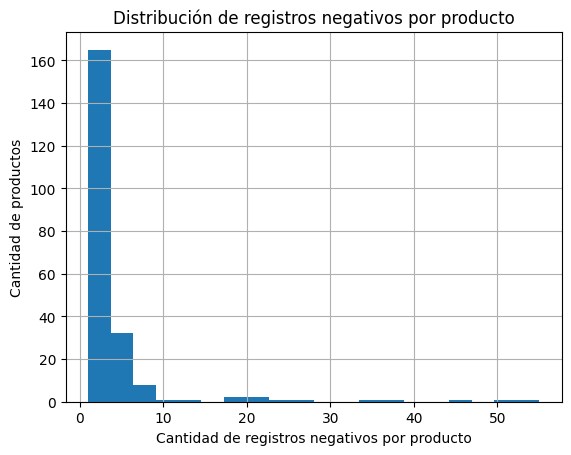

In [133]:
#Identificamos la distribucion de las filas con valores negativos, y si hay productos especificos que concentren estas unidades
ventas_negativas = df_ventas[df_ventas["Unidades"] < 0]
len(ventas_negativas)
agrupamiento1=ventas_negativas.groupby("ID_PRODUCTO").size()
agrupamiento2=ventas_negativas.groupby("ID_PRODUCTO")["Unidades"].sum()

#En el primer caso agrupamos en orden descendente, porque quremos la mayor cantidad de filas
print(agrupamiento1.sort_values(ascending=False).head(10))
#En el segundo agrupamiento ordenamos por orden ascendente porque son unidades negativas, y queremos ver los productos que mas unidades negativas tienen
print(agrupamiento2.sort_values(ascending=True).head(10))


agrupamiento1.hist(bins=20)

plt.title("Distribución de registros negativos por producto")
plt.xlabel("Cantidad de registros negativos por producto")
plt.ylabel("Cantidad de productos")
plt.show()



In [134]:
#Primero chequeamos que cuantas filas con unidades en 0 hay, para hacer una validacion contra la cantidad de filas pre y post

print((df_ventas["Unidades"]==0).sum())

sin_ceros = (df_ventas[df_ventas["Unidades"]!=0]).reset_index(drop=True)

sin_ceros.info()
df_ventas.info()


1645
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143873 entries, 0 to 143872
Data columns (total 3 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   ID_PRODUCTO  143873 non-null  int64
 1   ID_TIENDA    143873 non-null  int64
 2   Unidades     143873 non-null  int64
dtypes: int64(3)
memory usage: 3.3 MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145518 entries, 0 to 145517
Data columns (total 3 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   ID_PRODUCTO  145518 non-null  int64
 1   ID_TIENDA    145518 non-null  int64
 2   Unidades     145518 non-null  int64
dtypes: int64(3)
memory usage: 3.3 MB


In [135]:
#Borrammos todas las unidades iguales a 0 (por ahora mantenemos negativas y positivas)
df_ventas = (df_ventas[df_ventas["Unidades"]!=0]).reset_index(drop=True)
df_ventas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143873 entries, 0 to 143872
Data columns (total 3 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   ID_PRODUCTO  143873 non-null  int64
 1   ID_TIENDA    143873 non-null  int64
 2   Unidades     143873 non-null  int64
dtypes: int64(3)
memory usage: 3.3 MB


In [136]:
#Vamos a revisar los codigos que tienen unidades negativas

ventas_negativas = df_ventas[df_ventas["Unidades"]<0]
ventas_negativas.info()
len(ventas_negativas["ID_PRODUCTO"].unique())

prod_neg = df_productos[df_productos["Codigo Prod."].isin(ventas_negativas["ID_PRODUCTO"])]

print(prod_neg.value_counts())

<class 'pandas.core.frame.DataFrame'>
Index: 834 entries, 64 to 143508
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   ID_PRODUCTO  834 non-null    int64
 1   ID_TIENDA    834 non-null    int64
 2   Unidades     834 non-null    int64
dtypes: int64(3)
memory usage: 26.1 KB
Codigo Prod.  Producto                     productos.familia  productos.unidadnegocio  productos.famtablero  productos.untablero  P c IVA     
10001.0       Whopper con carne 4.4        CORE               ADULTOS                  WHOPPER               ALC                  8310.224484     1
10025.0       WhopperExtreme               CORE               ADULTOS                  WHOPPER               ALC                  15419.132061    1
10070.0       Chili King Doble             PREMIUM            ADULTOS                  CHILI KING            ALC                  0.000000        1
10072.0       Napolitano XL DBL con Huevo  PREMIUM            ADULTOS  

In [137]:
#Vamos a revisar valores faltantes en las 3 tablas

display(df_ventas.isnull().sum())

display(df_productos.isnull().sum())

display(df_tiendas.isnull().sum())


,0
ID_PRODUCTO,0
ID_TIENDA,0
Unidades,0


,0
Codigo Prod.,6
Producto,1
productos.familia,16
productos.unidadnegocio,2
productos.famtablero,43
productos.untablero,7
P c IVA,0


,0
ID_TIENDA,0
Nombre_Tienda,0
Region,0
Tipo_Tienda,0


el maestro de Tiendas parece estar correcto. No tiene valores nulos, pero en la tabla de ventas y en el maestro de productos si hay nulos

In [138]:
# vamos a revisar codigos repetidos en el maestro de productos

display(df_productos["Codigo Prod."].nunique())
productos_duplicados = df_productos[df_productos["Codigo Prod."].duplicated(keep=False)]

len(productos_duplicados)
display(productos_duplicados.head(20))



4405

,Codigo Prod.,Producto,productos.familia,productos.unidadnegocio,productos.famtablero,productos.untablero,P c IVA
248,NaN,Carne Mega,MODIFICADORES,ADULTOS,CARNE,EXTRA,0.0
249,NaN,Carne Whopper,MODIFICADORES,ADULTOS,CARNE,EXTRA,0.0
250,NaN,Adicional Panceta,MODIFICADORES,ADULTOS,FIAMBRE,EXTRA,0.0
1483,NaN,Bacon King XL,PREMIUM,ADULTOS,BACON KING,ALC,0.0
1501,NaN,*Cono DDL,VALOR,POSTRES,CREMA,CONTADOR,0.0
1502,NaN,*Cono Mixto,VALOR,POSTRES,CREMA,CONTADOR,0.0


Todos los codigos repetidos en el maestro de productos son codigos nulos --> ahora vamos a ver si el nombre de esos productos tienen algun codigo asignado que no sea nulo

In [139]:
#Separamos en dos arrays - productos que tienen codigo y productos que NO tienen codigo
productos_sin_codigo = df_productos[df_productos["Codigo Prod."].isna()]

productos_con_codigo = df_productos[df_productos["Codigo Prod."].notna()]

nombres_repetidos = productos_sin_codigo[productos_sin_codigo["Producto"].isin(productos_con_codigo["Producto"])]

codigos_por_nombre = (
    df_productos.groupby("Producto")["Codigo Prod."]
    .apply(list)
)

display(
    productos_sin_codigo[["Producto"]]
    .join(codigos_por_nombre.rename("Codigos_asociados"), on="Producto")
)



,Producto,Codigos_asociados
248,Carne Mega,"[nan, 110017.0]"
249,Carne Whopper,"[nan, 110019.0, 19901.0]"
250,Adicional Panceta,"[nan, 110020.0, 19903.0]"
1483,Bacon King XL,"[nan, 101157.0]"
1501,*Cono DDL,"[nan, 108062.0]"
1502,*Cono Mixto,"[nan, 108063.0]"


Todos los codigos nulos tienen una descripcion igual en otra fila pero con un codigo asignado. Por ende pueden eliminarse

In [140]:
#Se eliminan 6 filas sin código. Todas corresponden a productos que ya figuran en el maestro con un código válido.

productos_limpio=df_productos.dropna(subset=["Codigo Prod."]).reset_index(drop=True)

productos_limpio.shape

productos_limpio["Codigo Prod."] = productos_limpio["Codigo Prod."].astype(int)

productos_limpio.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4405 entries, 0 to 4404
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Codigo Prod.             4405 non-null   int64  
 1   Producto                 4404 non-null   object 
 2   productos.familia        4389 non-null   object 
 3   productos.unidadnegocio  4403 non-null   object 
 4   productos.famtablero     4362 non-null   object 
 5   productos.untablero      4398 non-null   object 
 6   P c IVA                  4405 non-null   float64
dtypes: float64(1), int64(1), object(5)
memory usage: 241.0+ KB


In [141]:
#Revisamos que el nombre de producto que se nulo

prod=productos_limpio[productos_limpio["Producto"].isna()]

display(prod)

#Vemos si este codigo tiene venta en Df_ventas

tiene = df_ventas[df_ventas['ID_PRODUCTO']==19675]

display(tiene)

#No esta en el df_ventas - no es un producto que tengamos que catalogar - probablemente una prueba se elimina

productos_limpio = productos_limpio.dropna(subset=["Producto"]).reset_index(drop=True)
productos_limpio.info()


,Codigo Prod.,Producto,productos.familia,productos.unidadnegocio,productos.famtablero,productos.untablero,P c IVA
3405,19675,NaN,-,-,-,-,0.0


,ID_PRODUCTO,ID_TIENDA,Unidades


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4404 entries, 0 to 4403
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Codigo Prod.             4404 non-null   int64  
 1   Producto                 4404 non-null   object 
 2   productos.familia        4388 non-null   object 
 3   productos.unidadnegocio  4402 non-null   object 
 4   productos.famtablero     4361 non-null   object 
 5   productos.untablero      4397 non-null   object 
 6   P c IVA                  4404 non-null   float64
dtypes: float64(1), int64(1), object(5)
memory usage: 241.0+ KB


In [142]:
#se renombran las columnas de la base de ventas y la base de productos

productos_limpio = productos_limpio.rename(columns={"Codigo Prod.":"id_producto","Producto":"nombre_producto","P c IVA":"precio_unitario"})
productos_limpio.columns

df_ventas=df_ventas.rename(columns={"ID_PRODUCTO":"id_producto","ID_TIENDA":"id_tienda","Unidades":"cantidad"})
df_ventas.columns

df_ventas["fecha"]="2026/02/01"
df_ventas.info()

#Convertimos la fecha de texto a datetime
df_ventas["fecha"] = pd.to_datetime(df_ventas["fecha"])
df_ventas.head()

#Se valida que la tabla de ventas tiene fecha en formato fecha, y todas las columnas renombradas sin valores nulos

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143873 entries, 0 to 143872
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   id_producto  143873 non-null  int64 
 1   id_tienda    143873 non-null  int64 
 2   cantidad     143873 non-null  int64 
 3   fecha        143873 non-null  object
dtypes: int64(3), object(1)
memory usage: 4.4+ MB


,id_producto,id_tienda,cantidad,fecha
0,10001,7672,2,2026-02-01
1,10001,7966,1,2026-02-01
2,10001,8059,5,2026-02-01
3,10001,8145,6,2026-02-01
4,10001,8409,1,2026-02-01


In [143]:
#Clasificamos los nulos de la bas de productos
productos_limpio.info()
productos_limpio[["productos.familia","productos.unidadnegocio","productos.famtablero","productos.untablero"]]= productos_limpio[["productos.familia","productos.unidadnegocio","productos.famtablero","productos.untablero"]].fillna("SIN CLASIFICAR")
productos_limpio.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4404 entries, 0 to 4403
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_producto              4404 non-null   int64  
 1   nombre_producto          4404 non-null   object 
 2   productos.familia        4388 non-null   object 
 3   productos.unidadnegocio  4402 non-null   object 
 4   productos.famtablero     4361 non-null   object 
 5   productos.untablero      4397 non-null   object 
 6   precio_unitario          4404 non-null   float64
dtypes: float64(1), int64(1), object(5)
memory usage: 241.0+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4404 entries, 0 to 4403
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_producto              4404 non-null   int64  
 1   nombre_producto          4404 non-null   object 
 2   productos.familia

In [144]:
#Revisamos nulos disfrazados

(productos_limpio[["productos.familia","productos.unidadnegocio","productos.famtablero","productos.untablero"]]=="-").sum()

#Tambien vamos a catalogarlos como SIN CLASIFICAR - para su envio al equipo de producto

productos_limpio[["productos.familia","productos.unidadnegocio","productos.famtablero","productos.untablero"]]=productos_limpio[["productos.familia","productos.unidadnegocio","productos.famtablero","productos.untablero"]].replace("-","SIN CLASIFICAR")

(productos_limpio[["productos.familia","productos.unidadnegocio","productos.famtablero","productos.untablero"]]=="-").sum()


,0
productos.familia,0
productos.unidadnegocio,0
productos.famtablero,0
productos.untablero,0


In [145]:
productos_limpio[["nombre_producto","productos.familia","productos.unidadnegocio","productos.famtablero","productos.untablero"]]=productos_limpio[["nombre_producto","productos.familia","productos.unidadnegocio","productos.famtablero","productos.untablero"]].astype(str)

In [146]:
#Revisamos si en el maestro de tiendas hay valores duplicados

tienda_dupli = df_tiendas[df_tiendas["ID_TIENDA"].duplicated(keep=False)]
len(tienda_dupli)

#Renombramos la columna id_tienda
df_tiendas = df_tiendas.rename(columns={"ID_TIENDA":"id_tienda"})

El maestro de tiendas no tiene valores nulos ni valores duplicados

Tenemos todos los maestros limpios, sin nulos ni valores duplicados y con las columnas bien identificadas

se procede a mergear

In [147]:
display(df_ventas.info())
display(productos_limpio.info())
display(df_tiendas.info())

df_final_ventas = df_ventas.merge(productos_limpio,on="id_producto",how="left",indicator=True,validate="many_to_one")

df_final_ventas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143873 entries, 0 to 143872
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   id_producto  143873 non-null  int64         
 1   id_tienda    143873 non-null  int64         
 2   cantidad     143873 non-null  int64         
 3   fecha        143873 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(3)
memory usage: 4.4 MB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4404 entries, 0 to 4403
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_producto              4404 non-null   int64  
 1   nombre_producto          4404 non-null   object 
 2   productos.familia        4404 non-null   object 
 3   productos.unidadnegocio  4404 non-null   object 
 4   productos.famtablero     4404 non-null   object 
 5   productos.untablero      4404 non-null   object 
 6   precio_unitario          4404 non-null   float64
dtypes: float64(1), int64(1), object(5)
memory usage: 241.0+ KB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109 entries, 0 to 108
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   id_tienda      109 non-null    int64 
 1   Nombre_Tienda  109 non-null    object
 2   Region         109 non-null    object
 3   Tipo_Tienda    109 non-null    object
dtypes: int64(1), object(3)
memory usage: 3.5+ KB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143873 entries, 0 to 143872
Data columns (total 11 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   id_producto              143873 non-null  int64         
 1   id_tienda                143873 non-null  int64         
 2   cantidad                 143873 non-null  int64         
 3   fecha                    143873 non-null  datetime64[ns]
 4   nombre_producto          143873 non-null  object        
 5   productos.familia        143873 non-null  object        
 6   productos.unidadnegocio  143873 non-null  object        
 7   productos.famtablero     143873 non-null  object        
 8   productos.untablero      143873 non-null  object        
 9   precio_unitario          143873 non-null  float64       
 10  _merge                   143873 non-null  category      
dtypes: category(1), datetime64[ns](1), float64(1), int64(3), object(5)
memory usag

In [148]:
#Todas los codigos de la base de ventas estan en el maestro de productos, y no hay duplicados
df_final_ventas["_merge"].value_counts()

#eliminamos la columna de "-merge" que validaba
df_final_ventas = df_final_ventas.drop(columns="_merge")
df_final_ventas.columns

Index(['id_producto', 'id_tienda', 'cantidad', 'fecha', 'nombre_producto',
       'productos.familia', 'productos.unidadnegocio', 'productos.famtablero',
       'productos.untablero', 'precio_unitario'],
      dtype='object')

In [149]:
df_final_ventas = df_final_ventas.merge(df_tiendas,on="id_tienda",how="left",indicator=True,validate="many_to_one")

df_final_ventas.columns


Index(['id_producto', 'id_tienda', 'cantidad', 'fecha', 'nombre_producto',
       'productos.familia', 'productos.unidadnegocio', 'productos.famtablero',
       'productos.untablero', 'precio_unitario', 'Nombre_Tienda', 'Region',
       'Tipo_Tienda', '_merge'],
      dtype='object')

In [150]:
# Otra vez, no hay ningun ID_tienda en la base de ventas que no este en la base de tiendas
df_final_ventas["_merge"].value_counts()

#se elimina la columna de _merge y nos quedamos con la tabla final
df_final_ventas=df_final_ventas.drop(columns="_merge")


In [151]:
df_final_ventas.info()

#Renombramos algunas columnas que quedaron con mayuscula

df_final_ventas= df_final_ventas.rename(columns={"Nombre_Tienda":"nombre_tienda","Region":"region","Tipo_Tienda":"tipo_tienda"})

df_final_ventas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143873 entries, 0 to 143872
Data columns (total 13 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   id_producto              143873 non-null  int64         
 1   id_tienda                143873 non-null  int64         
 2   cantidad                 143873 non-null  int64         
 3   fecha                    143873 non-null  datetime64[ns]
 4   nombre_producto          143873 non-null  object        
 5   productos.familia        143873 non-null  object        
 6   productos.unidadnegocio  143873 non-null  object        
 7   productos.famtablero     143873 non-null  object        
 8   productos.untablero      143873 non-null  object        
 9   precio_unitario          143873 non-null  float64       
 10  Nombre_Tienda            143873 non-null  object        
 11  Region                   143873 non-null  object        
 12  Tipo_Tienda     

In [152]:
#Negativos en la cantidad de ventas - vamos a analizar que tipologia tienen y que hacemos

#Vamos a revisar todas las unidades negativas y con precio cercano a 0, para eliminar
unidades_neg = df_final_ventas[(df_final_ventas["cantidad"]<0)&(df_final_ventas["precio_unitario"]>1)]

unidades_neg.value_counts(subset="productos.untablero")

len(unidades_neg)
display(unidades_neg)

#Hay productos con unidades negativas que tienen precio de venta, y las mismas representan devoluciones de producto. Las mantenemos para el calculo de venta total

#Eliminamos todos los registros de SISTEMAS para el calculo de la venta, porque representan ajustes manuales financieros

sistemas = df_final_ventas[df_final_ventas["productos.untablero"] =="SISTEMAS"]

len(sistemas)
sistemas.value_counts(subset="nombre_producto")

venta_sistemas=(sistemas["cantidad"]*sistemas["precio_unitario"]).sum()
venta=(df_final_ventas["cantidad"]*df_final_ventas["precio_unitario"]).sum()
print(venta_sistemas)
print(venta)
print(venta_sistemas/venta*100)



,id_producto,id_tienda,cantidad,fecha,nombre_producto,productos.familia,productos.unidadnegocio,productos.famtablero,productos.untablero,precio_unitario,nombre_tienda,region,tipo_tienda
64,10001,25004,-1,2026-02-01,Whopper con carne 4.4,CORE,ADULTOS,WHOPPER,ALC,8310.224484,Local 073,Interior,Local a la calle
843,10025,25004,-1,2026-02-01,WhopperExtreme,CORE,ADULTOS,WHOPPER,ALC,15419.132061,Local 073,Interior,Local a la calle
1035,10079,16141,-1,2026-02-01,BBQBacon+papR,COUPONING,ADULTOS,BBQ BaconKing XL,ALC,27733.596080,Local 092,Interior,Local a la calle
1084,10079,23752,-1,2026-02-01,BBQBacon+papR,COUPONING,ADULTOS,BBQ BaconKing XL,ALC,27733.596080,Local 097,Interior,Local a la calle
1086,10079,23893,-1,2026-02-01,BBQBacon+papR,COUPONING,ADULTOS,BBQ BaconKing XL,ALC,27733.596080,Local 066,GBA Oeste,Local a la calle
...,...,...,...,...,...,...,...,...,...,...,...,...,...
143504,9106098,30091,-1,2026-02-01,Factura A a Emitir,SISTEMAS,SISTEMAS,SISTEMAS,SISTEMAS,40998.097750,Local 087,GBA Sur,Drive Thru
143505,9106098,31874,-1,2026-02-01,Factura A a Emitir,SISTEMAS,SISTEMAS,SISTEMAS,SISTEMAS,40998.097750,Local 088,GBA Norte,Shopping
143506,9106098,31924,-3,2026-02-01,Factura A a Emitir,SISTEMAS,SISTEMAS,SISTEMAS,SISTEMAS,40998.097750,Local 089,Interior,Food Court
143507,9106098,32535,-4,2026-02-01,Factura A a Emitir,SISTEMAS,SISTEMAS,SISTEMAS,SISTEMAS,40998.097750,Local 090,GBA Oeste,Shopping


-6477139.11361428
22001291406.05302
-0.02943981330037873


In [153]:
#La venta asociada a conceptos de ajustes y sistemas pesa alrededor de un 0,03% - se desestima

df_final_ventas=df_final_ventas[df_final_ventas["productos.untablero"]!="SISTEMAS"].reset_index(drop=True)

df_final_ventas.shape

(142922, 13)

In [154]:
#creamos la columna venta para cada producto

df_final_ventas["total_venta"]=df_final_ventas['cantidad']*df_final_ventas["precio_unitario"]

In [155]:
#Validamos que no quedaron nulos en la base
df_final_ventas.isnull().sum()

,0
id_producto,0
id_tienda,0
cantidad,0
fecha,0
nombre_producto,0
productos.familia,0
productos.unidadnegocio,0
productos.famtablero,0
productos.untablero,0
precio_unitario,0


In [156]:
#Exportmaos el data frame a parquet

df_final_ventas.to_parquet("ventas_consolidadas.parquet", index=False)


In [157]:
prueba_parquet = pd.read_parquet("ventas_consolidadas.parquet")
print(prueba_parquet.shape)

# Tiene el mismo tamaño / filas
Parquet_Bytes = os.path.getsize("ventas_consolidadas.parquet")
print("Memoria en MB OPTIMIZADO:", round(Parquet_Bytes / (1024 ** 2), 4))

print("Memoria en MB archivo NO OPTIMIZADO:", round(peso_bytes_antes / (1024 ** 2), 4))

(142922, 14)
Memoria en MB OPTIMIZADO: 0.7911
Memoria en MB archivo NO OPTIMIZADO: 2.2313


El CSV pesa 2,23 MB con 3 columnas y el parquet 0,79 MB con 14 columnas. Es un 65% menos de peso con casi 5 veces más información